# 🌊 El Niño & Sri Lanka Rainfall — 12-Month Forecast from Real NOAA Data

This notebook downloads **real, free NOAA climate data**, trains a simple machine-learning
model to forecast the **Oceanic Niño Index (ONI)** up to 12 months ahead, and turns that
forecast into a **month-by-month rainfall outlook for Sri Lanka**.

| Step | What happens |
|---|---|
| 1 | Download ONI, SOI, OLR, Pacific sea temperature and global rainfall (NOAA, 1979 → today) |
| 2 | Explore: ENSO history and how each region's rain responds to El Niño, month by month |
| 3 | Build features (past ONI, SOI, OLR, sea-temperature patterns, season) |
| 4 | Train one model per lead time (1–12 months) and **test it honestly** against two baselines |
| 5 | Forecast ONI for the next 12 months with uncertainty |
| 6 | Convert the ONI forecast into a Sri Lanka rainfall outlook |
| 7 | Regional risk of extreme rain/drought from observed history |
| 8 | Save all results |

**Run it:** open in Google Colab → *Runtime → Run all*. Takes a few minutes, no GPU needed.
First run downloads ~180 MB of data into `real_data/`.

In [1]:
!pip install -q netCDF4 xarray

In [2]:
import shutil, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("real_data");  DATA_DIR.mkdir(exist_ok=True)
OUT_DIR  = Path("outputs");    OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1 · Download real data (NOAA, no login needed)

| Variable | Meaning | Source |
|---|---|---|
| **ONI** | Sea-surface temperature anomaly in the central Pacific (Niño-3.4), 3-month mean. ≥ +0.5 °C = El Niño, ≤ −0.5 °C = La Niña | NOAA CPC |
| **SOI** | Air-pressure difference Tahiti − Darwin. Strongly negative during El Niño | NOAA CPC |
| **OLR** | Outgoing long-wave radiation over the equatorial Pacific. Negative = more cloud and rain there | NOAA CPC |
| **SST field** | Monthly sea-surface temperature map of the tropical Pacific | NOAA ERSST v5 |
| **Rainfall** | Monthly rainfall on a 2.5° global grid, averaged over 9 regions incl. Sri Lanka | GPCP v2.3 |

All anomalies are relative to the **1991–2020** average (the current WMO standard).
The ONI value dated month *m* is the average of months *m−1, m, m+1*.

In [3]:
CPC = "https://www.cpc.ncep.noaa.gov/data/indices/"
PSL = "https://downloads.psl.noaa.gov/Datasets/"

def download(url, name):
    """Download once, then reuse the cached copy in real_data/."""
    path = DATA_DIR / name
    if not path.exists():
        print("downloading", url)
        urllib.request.urlretrieve(url, path)
    return path

def read_oni():
    table = pd.read_csv(download(CPC + "oni.ascii.txt", "oni.txt"), sep=r"\s+")
    centre_month = {s: i + 1 for i, s in enumerate(
        ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"])}
    dates = pd.to_datetime(dict(year=table["YR"], month=table["SEAS"].map(centre_month), day=1))
    return pd.Series(table["ANOM"].values, index=dates)

def read_cpc_table(name, block):
    """CPC text tables: rows of YEAR + 12 monthly values (6 characters each), split into
    blocks such as raw / anomaly / standardized. Returns block number `block`."""
    blocks, rows = [], []
    for line in download(CPC + name, name).read_text().splitlines():
        if line[:4].isdigit():
            rows.append(line.ljust(76))
        elif rows:
            blocks.append(rows); rows = []
    if rows:
        blocks.append(rows)
    rows = blocks[block]
    values = [float(r[4 + 6 * m: 10 + 6 * m]) for r in rows for m in range(12)]
    s = pd.Series(values, index=pd.date_range(f"{rows[0][:4]}-01-01", periods=len(values), freq="MS"))
    return s.where(s > -999)          # -999.9 = not published yet

def anomaly(da):
    """Subtract the 1991–2020 average for each calendar month."""
    normal = da.sel(time=slice("1991", "2020")).groupby("time.month").mean("time")
    return (da.groupby("time.month") - normal).drop_vars("month")

oni = read_oni()
soi = read_cpc_table("soi", block=0)      # SOI anomaly
olr = read_cpc_table("olr", block=1)      # OLR anomaly, W/m², equator 160°E–160°W

sst = xr.open_dataset(download(PSL + "noaa.ersst.v5/sst.mnmean.nc", "ersst_v5.nc"),
                      drop_variables=["time_bnds"])["sst"]
sst = anomaly(sst.sel(time=slice("1979", None))).sortby("lat")
pacific = sst.sel(lat=slice(-30, 30), lon=slice(120, 280))      # 120°E → 80°W

rain = xr.open_dataset(download(PSL + "gpcp/precip.mon.mean.nc", "gpcp_precip.nc"),
                       drop_variables=["time_bnds", "lat_bnds", "lon_bnds"])["precip"]
rain = anomaly(rain) * 30.4                                       # mm/day → mm/month

downloading https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt
downloading https://www.cpc.ncep.noaa.gov/data/indices/soi
downloading https://www.cpc.ncep.noaa.gov/data/indices/olr
downloading https://downloads.psl.noaa.gov/Datasets/noaa.ersst.v5/sst.mnmean.nc
downloading https://downloads.psl.noaa.gov/Datasets/gpcp/precip.mon.mean.nc


### Regions
Each region is a latitude/longitude box (longitude in °E, 0–360). `impact` says which kind of
extreme rain month hurts that region most, and is used for the risk index in step 7.

In [4]:
REGIONS = {
    #                   lat S, lat N, lon W, lon E        impact
    "Sri Lanka":       ((  5.5,  10,   79.5,  82),  "flood + drought"),
    "South India":     ((  8,    20,   74,    82),  "drought"),
    "SE Asia":         ((-10,    15,   95,   130),  "drought"),
    "East Australia":  ((-35,   -15,  140,   155),  "drought"),
    "Southern Africa": ((-30,   -15,   20,    35),  "drought"),
    "East Africa":     (( -5,     5,   35,    45),  "flood"),
    "Peru & Ecuador":  ((-10,     0,  275,   285),  "flood"),
    "Central America": ((  8,    18,  268,   280),  "drought"),
    "Central Pacific": ((-10,     0,  180,   200),  "flood"),
}

def box_mean(da, box):
    lat_s, lat_n, lon_w, lon_e = box
    inside = da.where((da.lat >= lat_s) & (da.lat <= lat_n) &
                      (da.lon >= lon_w) & (da.lon <= lon_e), drop=True)
    return inside.weighted(np.cos(np.deg2rad(inside.lat))).mean(("lat", "lon")).to_series()

region_rain = pd.DataFrame({name: box_mean(rain, box) for name, (box, _) in REGIONS.items()})

### Combine everything into one monthly table
SOI, OLR and rainfall are sometimes published a month or two after ONI, so they are carried
forward for at most 2 months. ONI itself is never filled in.

In [5]:
data = pd.concat({"oni": oni, "soi": soi, "olr": olr}, axis=1).join(region_rain, how="inner")
data = data[data.index.isin(pacific.time.values)]
data[data.columns.drop("oni")] = data[data.columns.drop("oni")].ffill(limit=2)
data = data.dropna()

sst_maps = np.nan_to_num(pacific.sel(time=data.index).values)        # land → 0
sst_flat = sst_maps.reshape(len(data), -1)

print(f"{len(data)} months: {data.index[0]:%b %Y} → {data.index[-1]:%b %Y}")
print(f"SST maps: {sst_maps.shape}  (months, lat, lon)")
data.tail()

569 months: Jan 1979 → Sep 2026
SST maps: (569, 31, 81)  (months, lat, lon)


,oni,soi,olr,Sri Lanka,South India,SE Asia,East Australia,Southern Africa,East Africa,Peru & Ecuador,Central America,Central Pacific
2026-05-01,0.95,-1.5,-1.8,51.155277,20.329926,9.335563,8.739334,2.583398,-50.517910,-5.505869,-81.543610,-57.813740
2026-06-01,1.39,-2.4,-17.9,0.771041,-17.522982,-47.185707,-9.441575,-0.218865,3.692919,-9.622570,-57.499420,36.409546
2026-07-01,1.80,-4.0,-19.4,-44.215801,-32.498413,-35.516632,-9.627295,-2.781672,-8.779785,-5.702268,-4.330466,152.469391
2026-08-01,2.16,-1.8,-14.9,27.598639,-51.580791,-72.602692,0.010109,9.994956,-0.129742,-6.098726,-62.248596,115.183105
2026-09-01,2.46,-3.3,-16.4,-22.031546,-28.215393,-48.147404,-12.602952,35.812050,30.886950,-8.805902,-40.211170,145.964630


## 2 · Explore the data

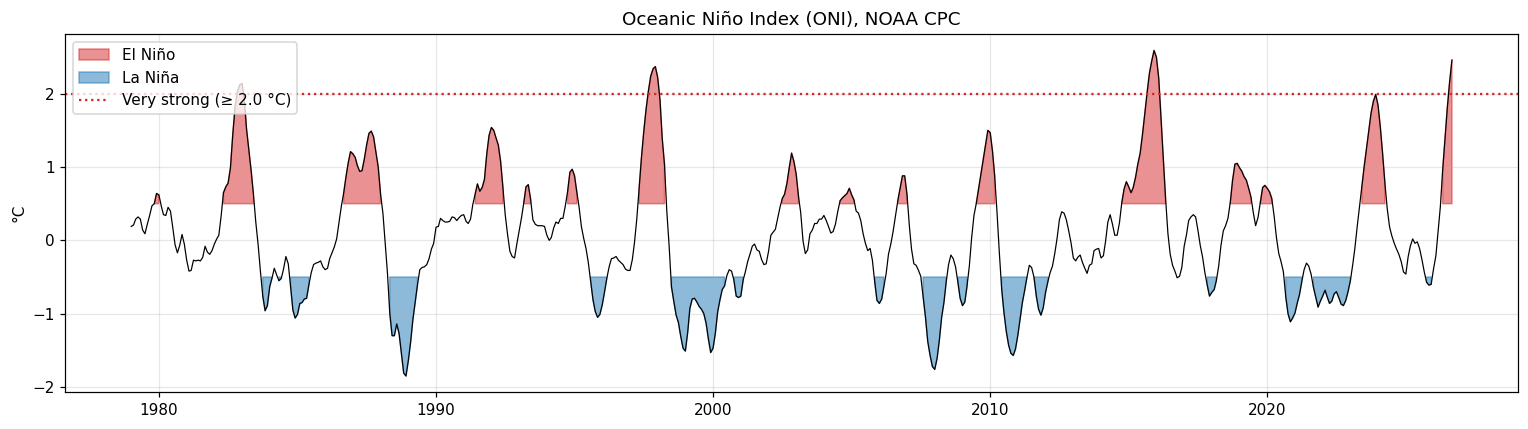

Strongest El Niño months on record:
2015-12-01    2.59
2016-01-01    2.50
2026-09-01    2.46
2015-11-01    2.45
1997-12-01    2.37


In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(data.index, data.oni, color="black", lw=0.8)
ax.fill_between(data.index, data.oni, 0.5, where=data.oni >= 0.5, color="tab:red", alpha=0.5, label="El Niño")
ax.fill_between(data.index, data.oni, -0.5, where=data.oni <= -0.5, color="tab:blue", alpha=0.5, label="La Niña")
ax.axhline(2.0, color="tab:red", ls=":", label="Very strong (≥ 2.0 °C)")
ax.set_title("Oceanic Niño Index (ONI), NOAA CPC"); ax.set_ylabel("°C"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(OUT_DIR / "1_oni_history.png"); plt.show()

print("Strongest El Niño months on record:")
print(data.oni.nlargest(5).round(2).to_string())

### How does El Niño change rainfall — and does it depend on the season?
Correlation between ONI and each region's rainfall, **separately for every calendar month**.
**Blue** = El Niño brings *more* rain that month, **red** = *less* rain.

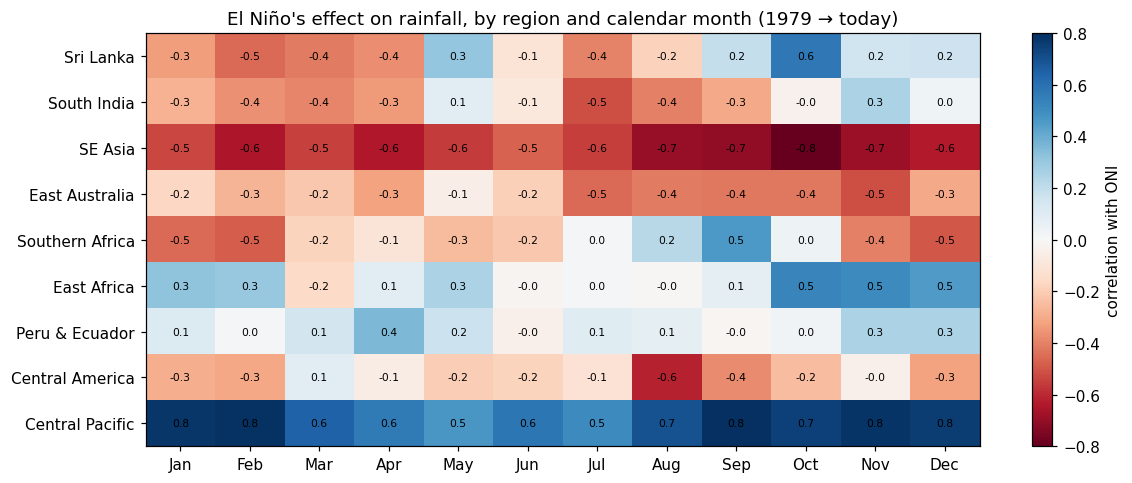

In [7]:
corr = pd.DataFrame({
    m: data[data.index.month == m][list(REGIONS)].corrwith(data.oni[data.index.month == m])
    for m in range(1, 13)})
corr.columns = pd.date_range("2000-01", periods=12, freq="MS").strftime("%b")

fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(corr.values, cmap="RdBu", vmin=-0.8, vmax=0.8, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(corr.columns)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
ax.grid(False)
for i in range(corr.shape[0]):
    for j in range(12):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="correlation with ONI")
ax.set_title("El Niño's effect on rainfall, by region and calendar month (1979 → today)")
plt.tight_layout(); plt.savefig(OUT_DIR / "2_rain_vs_oni_by_month.png"); plt.show()

**Reading it for Sri Lanka:** El Niño years tend to bring **extra rain in October–November**
(Maha season / north-east monsoon onset) and **drier January–April**. Over a whole year these
cancel out, which is why a single "El Niño = drought" rule is wrong for Sri Lanka and the
forecast below works month by month.

## 3 · Features

For each month *t* the model sees only things known at *t*:
- ONI now and 1, 2, 3, 6, 12 months ago
- SOI and OLR (now and 3-month average)
- The 5 main patterns of Pacific sea temperature (PCA of the SST maps)
- The season (sine/cosine of the month)

Target: ONI at *t + lead*, for lead = 1 … 12 months.

In [8]:
LEADS = range(1, 13)
N_PCS = 5

def make_features(df, sst_pcs):
    X = pd.DataFrame(index=df.index)
    for lag in (0, 1, 2, 3, 6, 12):
        X[f"oni_lag{lag}"] = df.oni.shift(lag)
    X["soi"], X["soi_3m"] = df.soi, df.soi.rolling(3).mean()
    X["olr"], X["olr_3m"] = df.olr, df.olr.rolling(3).mean()
    for i in range(sst_pcs.shape[1]):
        X[f"sst_pc{i + 1}"] = sst_pcs[:, i]
    X["month_sin"] = np.sin(2 * np.pi * df.index.month / 12)
    X["month_cos"] = np.cos(2 * np.pi * df.index.month / 12)
    return X

def new_model():
    return make_pipeline(StandardScaler(), Ridge(alpha=10.0))

## 4 · Train and test honestly

- **Train:** 1979 – 2014  **Test:** 2015 → today (the model never sees these years while training;
  they include the 2015–16 and 2023–24 strong El Niños)
- The SST patterns (PCA) are also learned from the training years only.
- The model has to beat two simple baselines to be useful:
  - **Persistence** — "ONI will stay what it is now"
  - **Climatology** — "ONI will be 0 (normal)"

Test error (RMSE, °C) on 2015 → today — lower is better
      Model  Persistence  Climatology  test months  Skill vs persistence
lead                                                                    
1     0.133        0.207        0.934          140                 0.355
2     0.255        0.401        0.936          139                 0.365
3     0.382        0.581        0.937          138                 0.342
4     0.497        0.741        0.938          137                 0.330
5     0.591        0.882        0.937          136                 0.330
6     0.672        1.001        0.935          135                 0.329
7     0.728        1.097        0.930          134                 0.337
8     0.758        1.169        0.922          133                 0.351
9     0.776        1.219        0.908          132                 0.364
10    0.780        1.248        0.890          131                 0.375
11    0.775        1.261        0.867          130                 0

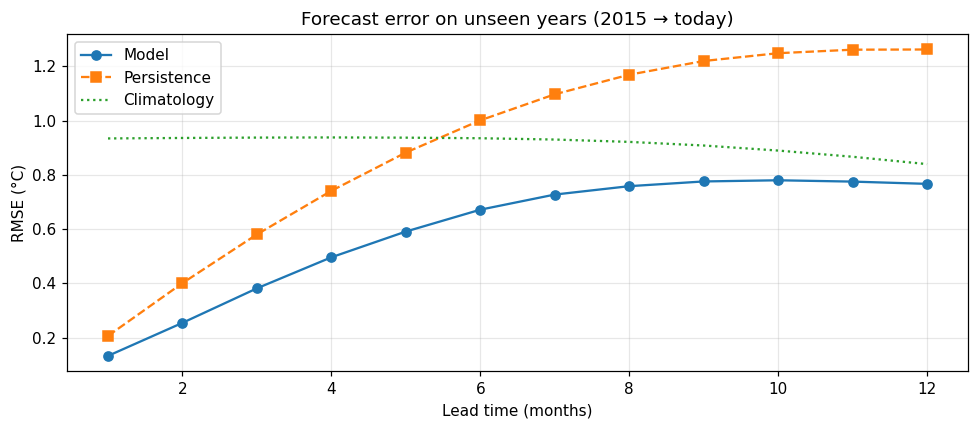

In [9]:
TRAIN_END = "2014-12-01"
train = data.index <= TRAIN_END

X_eval = make_features(data, PCA(N_PCS).fit(sst_flat[train]).transform(sst_flat))

rows = []
for lead in LEADS:
    y = data.oni.shift(-lead)
    ok = X_eval.notna().all(axis=1) & y.notna()
    tr, te = ok & train, ok & ~train
    pred = new_model().fit(X_eval[tr], y[tr]).predict(X_eval[te])
    rmse = lambda guess: float(np.sqrt(np.mean((y[te] - guess) ** 2)))
    rows.append({"lead": lead,
                 "Model": rmse(pred),
                 "Persistence": rmse(X_eval.loc[te, "oni_lag0"]),
                 "Climatology": rmse(0.0),
                 "test months": int(te.sum())})
skill = pd.DataFrame(rows).set_index("lead")
skill["Skill vs persistence"] = 1 - skill["Model"] / skill["Persistence"]
print("Test error (RMSE, °C) on 2015 → today — lower is better")
print(skill.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for col, style in [("Model", "o-"), ("Persistence", "s--"), ("Climatology", ":")]:
    ax.plot(skill.index, skill[col], style, label=col)
ax.set_xlabel("Lead time (months)"); ax.set_ylabel("RMSE (°C)")
ax.set_title("Forecast error on unseen years (2015 → today)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "3_forecast_skill.png"); plt.show()

Positive **skill vs persistence** means the model beats "no change". Error grows with lead time —
that is normal for ENSO forecasts (the well-known *spring predictability barrier* makes
forecasts made in March–May especially hard).

## 5 · Forecast the next 12 months

Now the models are re-trained on **all** data and run from the newest month.
Uncertainty: each lead's test RMSE from step 4 is used as its standard deviation,
giving a 10–90 % range and the probability of El Niño / La Niña.

Latest observed ONI: +2.46 °C (Sep 2026)

            lead  oni_mean  oni_p10  oni_p90  oni_sd  p_el_nino  p_la_nina
month                                                                     
2026-10-01     1      2.70     2.52     2.87    0.13       1.00       0.00
2026-11-01     2      2.78     2.45     3.10    0.26       1.00       0.00
2026-12-01     3      2.72     2.23     3.21    0.38       1.00       0.00
2027-01-01     4      2.53     1.89     3.16    0.50       1.00       0.00
2027-02-01     5      2.22     1.46     2.97    0.59       1.00       0.00
2027-03-01     6      1.83     0.97     2.69    0.67       0.98       0.00
2027-04-01     7      1.44     0.51     2.37    0.73       0.90       0.00
2027-05-01     8      1.05     0.08     2.02    0.76       0.77       0.02
2027-06-01     9      0.71    -0.28     1.71    0.78       0.61       0.06
2027-07-01    10      0.43    -0.57     1.43    0.78       0.47       0.12
2027-08-01    11      0.21    -0.78     1.21    0.78      

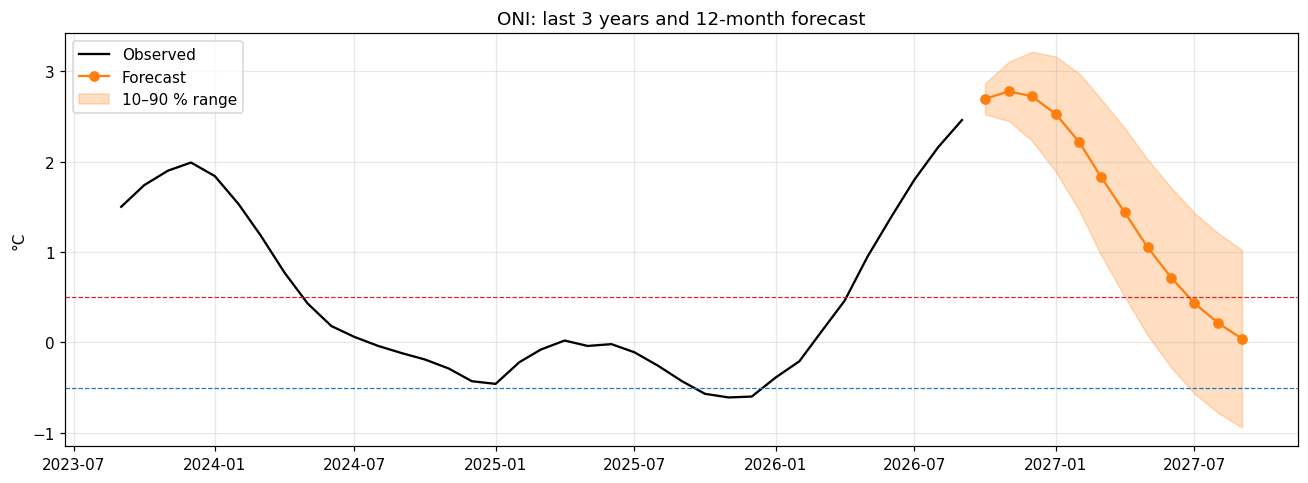

In [10]:
pca_all = PCA(N_PCS).fit(sst_flat)
X_all = make_features(data, pca_all.transform(sst_flat))
x_now = X_all.iloc[[-1]]
last = data.index[-1]

forecast = []
for lead in LEADS:
    y = data.oni.shift(-lead)
    ok = X_all.notna().all(axis=1) & y.notna()
    mean = float(new_model().fit(X_all[ok], y[ok]).predict(x_now)[0])
    sd = skill.loc[lead, "Model"]
    forecast.append({"month": last + pd.DateOffset(months=lead), "lead": lead,
                     "oni_mean": mean, "oni_p10": mean - 1.2816 * sd, "oni_p90": mean + 1.2816 * sd,
                     "oni_sd": sd,
                     "p_el_nino": 1 - norm.cdf(0.5, mean, sd),
                     "p_la_nina": norm.cdf(-0.5, mean, sd)})
forecast = pd.DataFrame(forecast).set_index("month")

print(f"Latest observed ONI: {data.oni.iloc[-1]:+.2f} °C ({last:%b %Y})\n")
print(forecast.round(2).to_string())

recent = data.oni[data.index >= last - pd.DateOffset(months=36)]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(recent.index, recent, "k-", label="Observed")
ax.plot(forecast.index, forecast.oni_mean, "o-", color="tab:orange", label="Forecast")
ax.fill_between(forecast.index, forecast.oni_p10, forecast.oni_p90, color="tab:orange", alpha=0.25, label="10–90 % range")
ax.axhline(0.5, color="tab:red", ls="--", lw=0.8); ax.axhline(-0.5, color="tab:blue", ls="--", lw=0.8)
ax.set_title("ONI: last 3 years and 12-month forecast"); ax.set_ylabel("°C"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(OUT_DIR / "4_oni_forecast.png"); plt.show()

## 6 · Sri Lanka rainfall outlook

For each calendar month, fit a straight line on 1979 → today:
**rain anomaly = a · ONI + b + noise**. Then, for every forecast month, draw 5 000 possible ONI
values from the forecast range, push them through that month's line (plus its natural noise),
and summarise.

Sri Lanka: rainfall outlook vs 1991–2020 normal (mm/month)

            rain_anomaly_mm  p10_mm  p90_mm  chance_wetter_than_normal  el_nino_effect_mm_per_degC
month                                                                                             
2026-10-01           132.52   51.89  212.40                       0.98                       47.31
2026-11-01            40.04  -61.65  142.32                       0.69                       12.54
2026-12-01            24.78  -98.24  149.60                       0.60                       14.78
2027-01-01           -61.18 -156.91   34.85                       0.20                      -25.16
2027-02-01           -67.83 -143.28    5.84                       0.12                      -31.72
2027-03-01           -46.59 -107.65   12.66                       0.16                      -27.66
2027-04-01           -47.15 -114.79   20.62                       0.19                      -32.87
2027-05-01            35.69  -45.41  118.31      

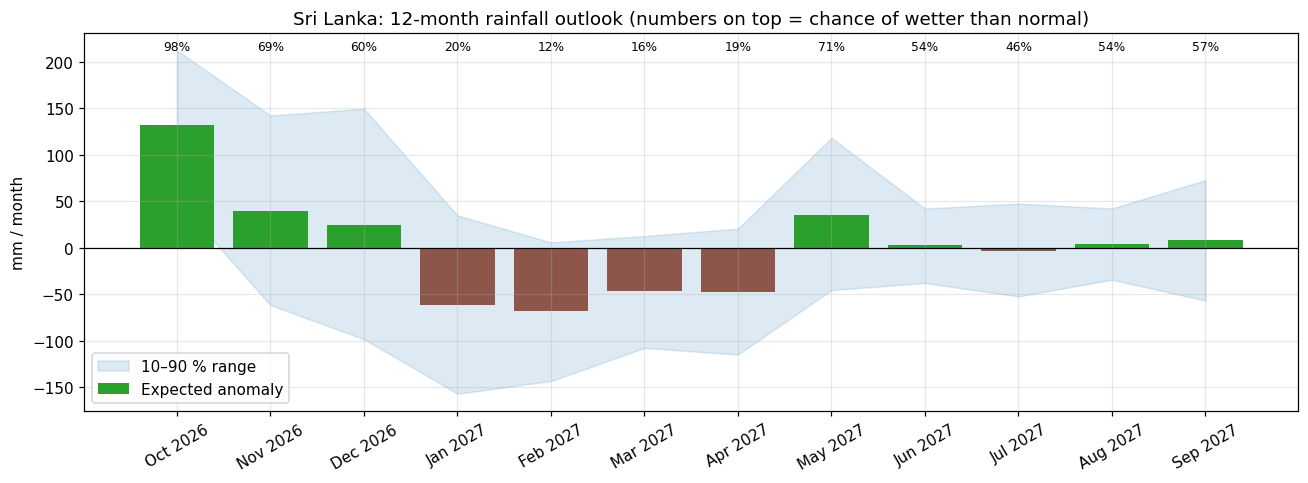

In [11]:
REGION = "Sri Lanka"
fits = {}
for m in range(1, 13):
    sel = data.index.month == m
    a, b = np.polyfit(data.oni[sel], data[REGION][sel], 1)
    noise = np.std(data[REGION][sel] - (a * data.oni[sel] + b))
    fits[m] = (a, b, noise)

N_SAMPLES = 5000
rows = []
for month, f in forecast.iterrows():
    a, b, noise = fits[month.month]
    oni_draws = rng.normal(f.oni_mean, f.oni_sd, N_SAMPLES)
    rain_draws = a * oni_draws + b + rng.normal(0, noise, N_SAMPLES)
    rows.append({"month": month,
                 "rain_anomaly_mm": rain_draws.mean(),
                 "p10_mm": np.percentile(rain_draws, 10),
                 "p90_mm": np.percentile(rain_draws, 90),
                 "chance_wetter_than_normal": (rain_draws > 0).mean(),
                 "el_nino_effect_mm_per_degC": a})
sl = pd.DataFrame(rows).set_index("month")
print(f"{REGION}: rainfall outlook vs 1991–2020 normal (mm/month)\n")
print(sl.round(2).to_string())

x = np.arange(len(sl))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(x, sl.p10_mm, sl.p90_mm, color="tab:blue", alpha=0.15, label="10–90 % range")
ax.bar(x, sl.rain_anomaly_mm, color=np.where(sl.rain_anomaly_mm > 0, "tab:green", "tab:brown"), label="Expected anomaly")
ax.axhline(0, color="black", lw=0.8)
for xi, p in zip(x, sl.chance_wetter_than_normal):
    ax.text(xi, ax.get_ylim()[1] * 0.92, f"{p:.0%}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(sl.index.strftime("%b %Y"), rotation=30)
ax.set_ylabel("mm / month")
ax.set_title(f"{REGION}: 12-month rainfall outlook (numbers on top = chance of wetter than normal)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(OUT_DIR / "5_sri_lanka_rain_outlook.png"); plt.show()

## 7 · Regional risk of extreme months

Risk index = how often a **1-in-5 extreme month** of the damaging kind (driest 20 % for drought,
wettest 20 % for flood, driest/wettest 10 % each for "flood + drought") actually happened in the
60 historical months whose ONI was closest to the value we ask about.

Normal odds are **0.20**. 0.40 means twice as likely as usual.

                 La Niña (−1.0)  Normal (0.0)  Moderate El Niño (+1.0)  Strong El Niño (+2.0)  Forecast peak (+2.8)
Sri Lanka                  0.25          0.10                     0.22                   0.22                  0.22
South India                0.15          0.10                     0.30                   0.28                  0.28
SE Asia                    0.02          0.13                     0.42                   0.75                  0.75
East Australia             0.10          0.18                     0.37                   0.30                  0.30
Southern Africa            0.10          0.18                     0.35                   0.45                  0.45
East Africa                0.17          0.20                     0.30                   0.33                  0.33
Peru & Ecuador             0.20          0.17                     0.18                   0.32                  0.32
Central America            0.12          0.17                     0.33  

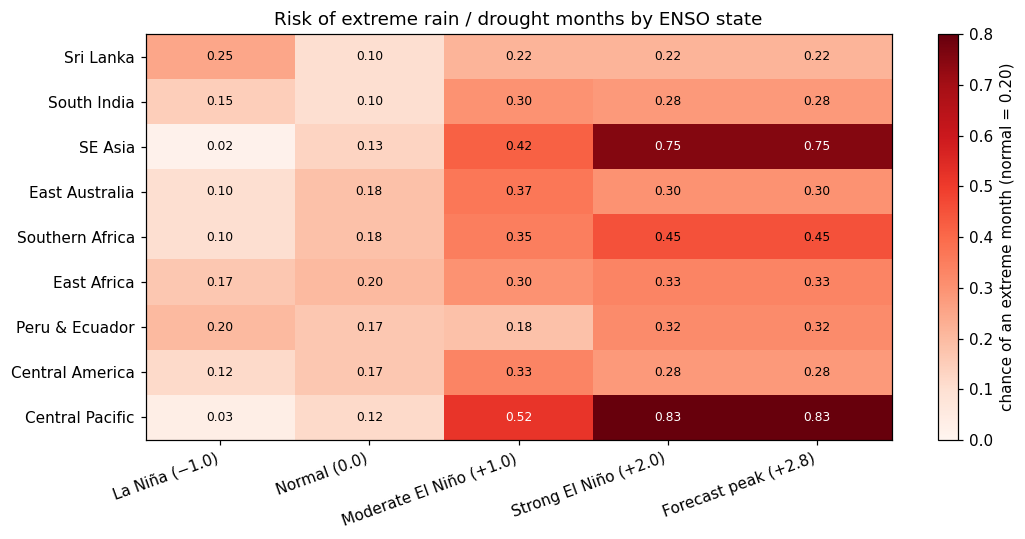


At the forecast peak:
  Central Pacific  0.83  VERY HIGH
  SE Asia          0.75  VERY HIGH
  Southern Africa  0.45  HIGH
  East Africa      0.33  normal
  Peru & Ecuador   0.32  normal
  East Australia   0.30  normal
  South India      0.28  normal
  Central America  0.28  normal
  Sri Lanka        0.22  normal


In [12]:
NEAREST = 60
HIGH, VERY_HIGH = 0.35, 0.50

def risk_index(oni_value, region):
    r = data[region].values
    impact = REGIONS[region][1]
    if impact == "drought":
        extreme = r <= np.percentile(r, 20)
    elif impact == "flood":
        extreme = r >= np.percentile(r, 80)
    else:
        extreme = (r <= np.percentile(r, 10)) | (r >= np.percentile(r, 90))
    nearest = np.argsort(np.abs(data.oni.values - oni_value))[:NEAREST]
    return extreme[nearest].mean()

scenarios = {"La Niña (−1.0)": -1.0, "Normal (0.0)": 0.0, "Moderate El Niño (+1.0)": 1.0,
             "Strong El Niño (+2.0)": 2.0,
             f"Forecast peak ({forecast.oni_mean.max():+.1f})": forecast.oni_mean.max()}
risk = pd.DataFrame({s: {r: risk_index(v, r) for r in REGIONS} for s, v in scenarios.items()})
print(risk.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(risk.values, cmap="Reds", vmin=0, vmax=0.8, aspect="auto")
ax.set_xticks(range(risk.shape[1])); ax.set_xticklabels(risk.columns, rotation=20, ha="right")
ax.set_yticks(range(risk.shape[0])); ax.set_yticklabels(risk.index); ax.grid(False)
for i in range(risk.shape[0]):
    for j in range(risk.shape[1]):
        v = risk.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v >= VERY_HIGH else "black")
plt.colorbar(im, label="chance of an extreme month (normal = 0.20)")
ax.set_title("Risk of extreme rain / drought months by ENSO state")
plt.tight_layout(); plt.savefig(OUT_DIR / "6_regional_risk.png"); plt.show()

level = lambda v: "VERY HIGH" if v >= VERY_HIGH else "HIGH" if v >= HIGH else "normal"
peak = risk.columns[-1]
print(f"\nAt the forecast peak:")
for region, v in risk[peak].sort_values(ascending=False).items():
    print(f"  {region:16s} {v:.2f}  {level(v)}")

## 8 · Save results

In [13]:
forecast.round(3).to_csv(OUT_DIR / "oni_forecast.csv")
sl.round(3).to_csv(OUT_DIR / "sri_lanka_rain_outlook.csv")
skill.round(4).to_csv(OUT_DIR / "forecast_skill.csv")
risk.round(3).to_csv(OUT_DIR / "regional_risk.csv")
corr.round(3).to_csv(OUT_DIR / "rain_vs_oni_by_month.csv")
data.round(3).to_csv(OUT_DIR / "monthly_dataset.csv")

archive = shutil.make_archive("results", "zip", OUT_DIR)     # zip is created NEXT TO outputs/
print("Saved:", *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n  ")
print("\nDownload everything:", archive)

Saved:
  1_oni_history.png
  2_rain_vs_oni_by_month.png
  3_forecast_skill.png
  4_oni_forecast.png
  5_sri_lanka_rain_outlook.png
  6_regional_risk.png
  forecast_skill.csv
  monthly_dataset.csv
  oni_forecast.csv
  rain_vs_oni_by_month.csv
  regional_risk.csv
  sri_lanka_rain_outlook.csv

Download everything: /content/results.zip


## Limitations
- The ONI model is linear (Ridge regression) — simple and transparent, but official forecasts
  (NOAA CPC, IRI, ECMWF) use full ocean–atmosphere models. Compare with them before acting.
- GPCP rainfall is a 2.5° grid, so "Sri Lanka" is only ~2 grid cells — fine for island-wide
  signals, not for district-level detail.
- The rain–ONI relationship is fitted on ~47 years, i.e. only a handful of strong El Niños.